# UTKFace Eight-Group CNN Experiment

## Goal
This experiment trains the same CNN architecture used in the Face-Age-10K baseline on the UTKFace dataset.

We use eight age groups:
1. 01-10
2. 11-20
3. 21-30
4. 31-40
5. 41-55
6. 56-65
7. 66-80
8. 81+

The purpose is to examine how a different and larger dataset affects CNN age-group classification performance.

## Dataset
UTKFace contains face images with integer age labels encoded in each filename. We use the cropped 200 x 200 RGB images. The original dataset is for non-commercial research use.

In [1]:
from pathlib import Path
from PIL import Image
from collections import Counter
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reproducible experiment setting
SEED = 418
random.seed(SEED)
np.random.seed(SEED)

# This notebook is stored in the project folder.
PROJECT_FOLDER = Path.cwd()

# Folder containing the extracted UTKFace images.
UTKFACE_FOLDER = PROJECT_FOLDER / "UTKFace_source" / "extracted" / "UTKFace"

print("Project folder:", PROJECT_FOLDER)
print("UTKFace folder exists:", UTKFACE_FOLDER.exists())

image_paths = sorted(UTKFACE_FOLDER.glob("*.jpg"))
print("Number of UTKFace image files:", len(image_paths))
print("First filename:", image_paths[0].name)

Project folder: C:\Users\ASUS\Downloads\ENGR418_Facial_Age_Group_Estimation
UTKFace folder exists: True
Number of UTKFace image files: 23708
First filename: 100_0_0_20170112213500903.jpg.chip.jpg


In [2]:
# Convert an integer age into one of our eight project age groups.
def age_to_group(age):
    if 1 <= age <= 10:
        return "age 01-10"
    elif 11 <= age <= 20:
        return "age 11-20"
    elif 21 <= age <= 30:
        return "age 21-30"
    elif 31 <= age <= 40:
        return "age 31-40"
    elif 41 <= age <= 55:
        return "age 41-55"
    elif 56 <= age <= 65:
        return "age 56-65"
    elif 66 <= age <= 80:
        return "age 66-80"
    elif age >= 81:
        return "age 81+"
    else:
        return None

records = []

for image_path in image_paths:
    # UTKFace filenames begin with: age_gender_race_...
    age = int(image_path.name.split("_")[0])
    age_group = age_to_group(age)

    records.append({
        "file_name": image_path.name,
        "age": age,
        "age_group": age_group,
        "path": str(image_path)
    })

utk_table = pd.DataFrame(records)

print("Total records:", len(utk_table))
print("Age range:", utk_table["age"].min(), "to", utk_table["age"].max())
print("Missing age groups:", utk_table["age_group"].isna().sum())

class_counts = (
    utk_table["age_group"]
    .value_counts()
    .reindex([
        "age 01-10", "age 11-20", "age 21-30", "age 31-40",
        "age 41-55", "age 56-65", "age 66-80", "age 81+"
    ])
)

display(class_counts.to_frame(name="image_count"))

Total records: 23708
Age range: 1 to 116
Missing age groups: 0


,image_count
age_group,
age 01-10,3218
age 11-20,1659
age 21-30,7784
age 31-40,4339
age 41-55,3332
age 56-65,1677
age 66-80,1159
age 81+,540


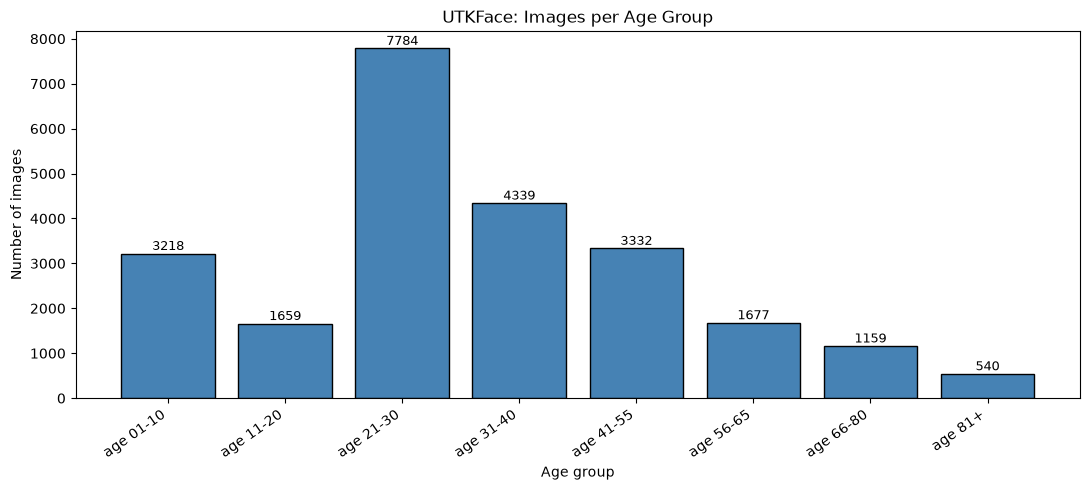

In [3]:
plt.figure(figsize=(11, 5))

plt.bar(
    class_counts.index,
    class_counts.values,
    color="steelblue",
    edgecolor="black"
)

plt.title("UTKFace: Images per Age Group")
plt.xlabel("Age group")
plt.ylabel("Number of images")
plt.xticks(rotation=35, ha="right")

for index, count in enumerate(class_counts.values):
    plt.text(index, count + 80, str(count), ha="center", fontsize=9)

plt.tight_layout()
plt.show()

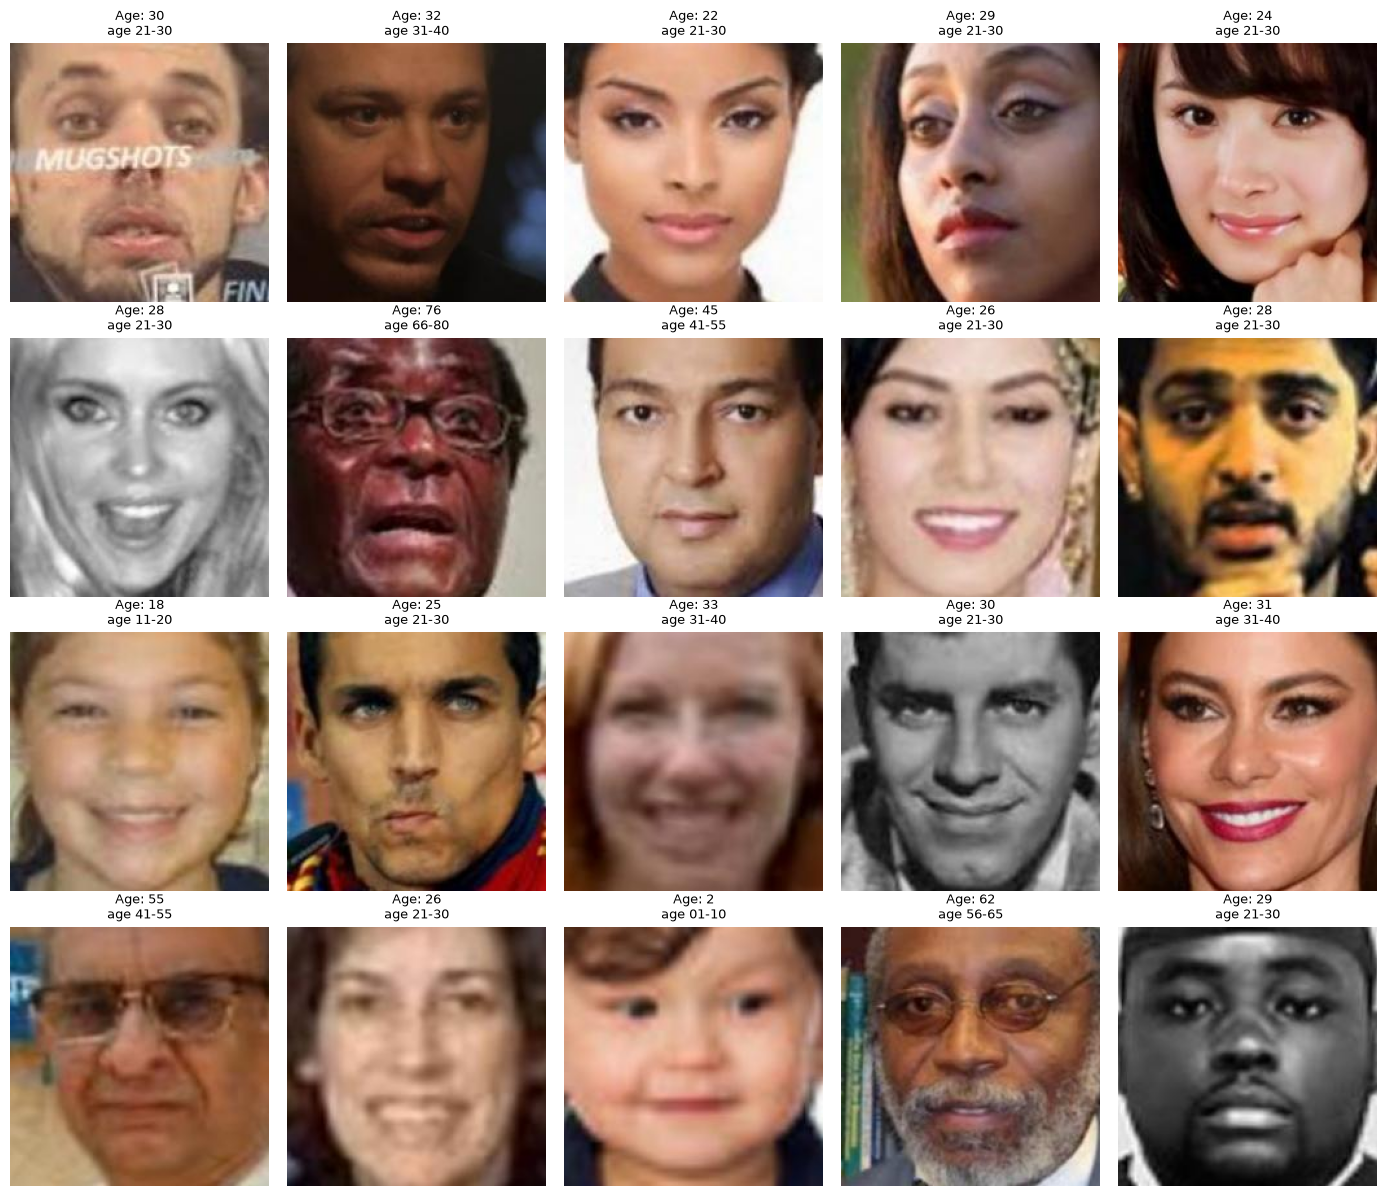

In [4]:
sample_indices = random.sample(
    range(len(utk_table)),
    k=20
)

fig, axes = plt.subplots(4, 5, figsize=(14, 12))

for axis, row_index in zip(axes.flat, sample_indices):
    row = utk_table.iloc[row_index]

    with Image.open(row["path"]) as image:
        axis.imshow(image.convert("RGB"))

    axis.set_title(
        f'Age: {row["age"]}\n{row["age_group"]}',
        fontsize=9
    )
    axis.axis("off")

plt.tight_layout()
plt.show()

In [5]:
image_sizes = Counter()
image_modes = Counter()
invalid_images = []

for image_path in image_paths:
    try:
        with Image.open(image_path) as image:
            image.load()  # Force the image file to be read.
            image_sizes[image.size] += 1
            image_modes[image.mode] += 1

    except Exception as error:
        invalid_images.append({
            "file_name": image_path.name,
            "error": type(error).__name__
        })

print("Images checked:", len(image_paths))
print("Unreadable images:", len(invalid_images))

print("\nImage dimensions:")
display(
    pd.DataFrame(
        image_sizes.items(),
        columns=["dimensions", "image_count"]
    )
)

print("\nImage colour modes:")
display(
    pd.DataFrame(
        image_modes.items(),
        columns=["mode", "image_count"]
    )
)

if invalid_images:
    print("\nFirst invalid-image records:")
    display(pd.DataFrame(invalid_images).head())

Images checked: 23708
Unreadable images: 0

Image dimensions:


,dimensions,image_count
0,"(200, 200)",23708



Image colour modes:


,mode,image_count
0,RGB,23708


In [6]:
from sklearn.model_selection import train_test_split

# First, reserve 15% of the dataset as the final test set.
train_validation_table, test_table = train_test_split(
    utk_table,
    test_size=0.15,
    random_state=SEED,
    stratify=utk_table["age_group"]
)

# Then, split the remaining 85% into 70% training and 15% validation.
train_table, validation_table = train_test_split(
    train_validation_table,
    test_size=0.15 / 0.85,
    random_state=SEED,
    stratify=train_validation_table["age_group"]
)

# Add a split label to every image record.
train_table = train_table.copy()
validation_table = validation_table.copy()
test_table = test_table.copy()

train_table["split"] = "train"
validation_table["split"] = "validation"
test_table["split"] = "test"

utk_split_table = pd.concat(
    [train_table, validation_table, test_table],
    ignore_index=True
)

print("Partition sizes:")
print(utk_split_table["split"].value_counts())

print("\nAge-group counts in each partition:")
split_counts = pd.crosstab(
    utk_split_table["age_group"],
    utk_split_table["split"]
)

display(
    split_counts.reindex([
        "age 01-10", "age 11-20", "age 21-30", "age 31-40",
        "age 41-55", "age 56-65", "age 66-80", "age 81+"
    ])
)

# Save the exact split for reproducible later training.
utk_split_table.to_csv(
    "data/splits/UTKFace_8Groups_split_indices.csv",
    index=False
)

print("\nSaved: data/splits/UTKFace_8Groups_split_indices.csv")

Partition sizes:
split
train         16594
validation     3557
test           3557
Name: count, dtype: int64

Age-group counts in each partition:


split,test,train,validation
age_group,,,
age 01-10,483,2252,483
age 11-20,249,1161,249
age 21-30,1168,5448,1168
age 31-40,651,3037,651
age 41-55,500,2332,500
age 56-65,251,1175,251
age 66-80,174,811,174
age 81+,81,378,81



Saved: data/splits/UTKFace_8Groups_split_indices.csv


In [7]:
train_files = set(train_table["file_name"])
validation_files = set(validation_table["file_name"])
test_files = set(test_table["file_name"])

assert train_files.isdisjoint(validation_files)
assert train_files.isdisjoint(test_files)
assert validation_files.isdisjoint(test_files)

assert len(train_files | validation_files | test_files) == len(utk_table)

print("Split check passed.")
print("No filename appears in more than one partition.")

Split check passed.
No filename appears in more than one partition.


## Prepare Images for CNN Training

Each image is resized to 200 × 200 pixels and converted into an RGB tensor. 
Pixel values are scaled from 0–255 to 0–1.

The CNN output has eight neurons, one for each age group.

In [8]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

LABEL_NAMES = [
    "age 01-10",
    "age 11-20",
    "age 21-30",
    "age 31-40",
    "age 41-55",
    "age 56-65",
    "age 66-80",
    "age 81+"
]

label_to_id = {
    label: index
    for index, label in enumerate(LABEL_NAMES)
}

# Convert each image into a PyTorch tensor.
image_transform = transforms.Compose([
    transforms.Resize((200, 200)),
    transforms.ToTensor()
])

class UTKFaceDataset(Dataset):
    def __init__(self, table, transform):
        self.table = table.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.table)

    def __getitem__(self, index):
        row = self.table.iloc[index]

        with Image.open(row["path"]) as image:
            image = image.convert("RGB")
            image_tensor = self.transform(image)

        label_id = label_to_id[row["age_group"]]

        return image_tensor, torch.tensor(label_id, dtype=torch.long)

train_dataset = UTKFaceDataset(train_table, image_transform)
validation_dataset = UTKFaceDataset(validation_table, image_transform)
test_dataset = UTKFaceDataset(test_table, image_transform)

BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Pixel value range:", images.min().item(), "to", images.max().item())
print("First 10 numeric labels:", labels[:10].tolist())

Image batch shape: torch.Size([64, 3, 200, 200])
Label batch shape: torch.Size([64])
Pixel value range: 0.0 to 1.0
First 10 numeric labels: [3, 3, 2, 0, 5, 2, 1, 3, 3, 4]


In [9]:
from torch import nn

class SmallAgeCNN(nn.Module):
    def __init__(self, number_of_classes):
        super().__init__()

        self.features = nn.Sequential(
            # First convolution block: 200 × 200 -> 100 × 100
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Second convolution block: 100 × 100 -> 50 × 50
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Third convolution block: 50 × 50 -> 25 × 25
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Convert each 25 × 25 feature map into one value.
            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=0.30),
            nn.Linear(128, number_of_classes)
        )

    def forward(self, images):
        features = self.features(images)
        return self.classifier(features)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = SmallAgeCNN(
    number_of_classes=len(LABEL_NAMES)
).to(device)

print("Device:", device)
print(model)

trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("\nTrainable parameters:", trainable_parameters)

Device: cuda
SmallAgeCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.3, inplace=False)
    (2): Linear(in_features=128, out_features=8, bias=True)
  )
)

Trainable parameters: 94280


In [10]:
from sklearn.metrics import accuracy_score, f1_score

# Count only training labels.
# Validation and test data must not affect class weights.
train_label_ids = train_table["age_group"].map(
    label_to_id
).to_numpy()

train_counts = np.bincount(
    train_label_ids,
    minlength=len(LABEL_NAMES)
)

# Smaller classes receive larger loss weights.
class_weights = len(train_label_ids) / (
    len(LABEL_NAMES) * train_counts
)

class_weights_tensor = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=device
)

weight_table = pd.DataFrame({
    "age_group": LABEL_NAMES,
    "training_images": train_counts,
    "loss_weight": class_weights.round(3)
})

display(weight_table)

loss_function = nn.CrossEntropyLoss(
    weight=class_weights_tensor
)

LEARNING_RATE = 1e-3

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

@torch.no_grad()
def evaluate_model(model, data_loader):
    model.eval()

    true_labels = []
    predicted_labels = []

    total_loss = 0.0
    total_images = 0

    for batch_images, batch_labels in data_loader:
        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)

        logits = model(batch_images)
        batch_loss = loss_function(logits, batch_labels)

        total_loss += batch_loss.item() * batch_labels.size(0)
        total_images += batch_labels.size(0)

        predictions = logits.argmax(dim=1)

        true_labels.extend(batch_labels.cpu().numpy())
        predicted_labels.extend(predictions.cpu().numpy())

    return {
        "loss": total_loss / total_images,
        "accuracy": accuracy_score(true_labels, predicted_labels),
        "macro_f1": f1_score(
            true_labels,
            predicted_labels,
            average="macro",
            zero_division=0
        ),
        "true_labels": np.array(true_labels),
        "predicted_labels": np.array(predicted_labels)
    }

,age_group,training_images,loss_weight
0,age 01-10,2252,0.921
1,age 11-20,1161,1.787
2,age 21-30,5448,0.381
3,age 31-40,3037,0.683
4,age 41-55,2332,0.889
5,age 56-65,1175,1.765
6,age 66-80,811,2.558
7,age 81+,378,5.487


In [11]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

model = SmallAgeCNN(
    number_of_classes=len(LABEL_NAMES)
).to(device)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

print("Model and optimizer reset with seed:", SEED)

Model and optimizer reset with seed: 418


## Train the Eight-Group CNN

The model trains for 10 epochs. After each epoch, performance is measured on the validation set.

The best checkpoint is selected using validation macro-F1. The test set is not used during training or model selection.

In [13]:
EPOCHS = 10

best_validation_macro_f1 = -1.0

best_model_path = (
    PROJECT_FOLDER /
    "models/utkface_8groups_cnn_best.pt"
)

training_history = []

for epoch in range(1, EPOCHS + 1):
    model.train()

    running_loss = 0.0
    images_seen = 0

    for batch_images, batch_labels in train_loader:
        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)

        optimizer.zero_grad()

        logits = model(batch_images)
        loss = loss_function(logits, batch_labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * batch_labels.size(0)
        images_seen += batch_labels.size(0)

    train_loss = running_loss / images_seen

    validation_results = evaluate_model(
        model,
        validation_loader
    )

    training_history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "validation_loss": validation_results["loss"],
        "validation_accuracy": validation_results["accuracy"],
        "validation_macro_f1": validation_results["macro_f1"]
    })

    if validation_results["macro_f1"] > best_validation_macro_f1:
        best_validation_macro_f1 = (
            validation_results["macro_f1"]
        )

        torch.save({
            "model_state_dict": model.state_dict(),
            "label_names": LABEL_NAMES,
            "seed": SEED,
            "validation_macro_f1": best_validation_macro_f1
        }, best_model_path)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"train loss {train_loss:.4f} | "
        f"validation loss {validation_results['loss']:.4f} | "
        f"validation accuracy {validation_results['accuracy']:.3f} | "
        f"validation macro-F1 "
        f"{validation_results['macro_f1']:.3f}"
    )

history_table = pd.DataFrame(training_history)

print("\nBest validation macro-F1:",
      round(best_validation_macro_f1, 3))

print("Saved best model to:", best_model_path)

Epoch 01/10 | train loss 2.0475 | validation loss 2.0250 | validation accuracy 0.300 | validation macro-F1 0.110
Epoch 02/10 | train loss 2.0231 | validation loss 1.9890 | validation accuracy 0.280 | validation macro-F1 0.193
Epoch 03/10 | train loss 2.0064 | validation loss 1.9989 | validation accuracy 0.337 | validation macro-F1 0.149
Epoch 04/10 | train loss 1.9796 | validation loss 1.9584 | validation accuracy 0.228 | validation macro-F1 0.197
Epoch 05/10 | train loss 1.9577 | validation loss 1.9401 | validation accuracy 0.259 | validation macro-F1 0.187
Epoch 06/10 | train loss 1.9377 | validation loss 1.9235 | validation accuracy 0.248 | validation macro-F1 0.206
Epoch 07/10 | train loss 1.9214 | validation loss 1.9011 | validation accuracy 0.315 | validation macro-F1 0.239
Epoch 08/10 | train loss 1.9015 | validation loss 1.8792 | validation accuracy 0.276 | validation macro-F1 0.216
Epoch 09/10 | train loss 1.8671 | validation loss 1.8404 | validation accuracy 0.361 | validatio

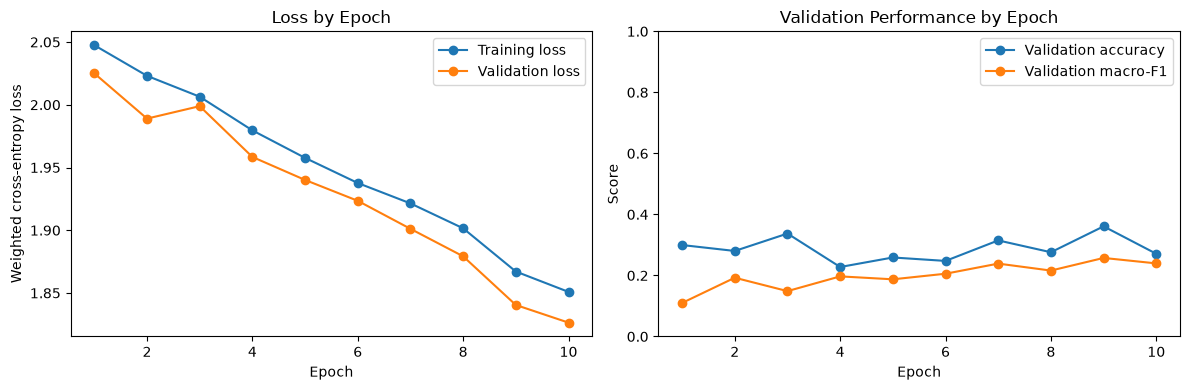

In [14]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 4)
)

axes[0].plot(
    history_table["epoch"],
    history_table["train_loss"],
    marker="o",
    label="Training loss"
)

axes[0].plot(
    history_table["epoch"],
    history_table["validation_loss"],
    marker="o",
    label="Validation loss"
)

axes[0].set_title("Loss by Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Weighted cross-entropy loss")
axes[0].legend()

axes[1].plot(
    history_table["epoch"],
    history_table["validation_accuracy"],
    marker="o",
    label="Validation accuracy"
)

axes[1].plot(
    history_table["epoch"],
    history_table["validation_macro_f1"],
    marker="o",
    label="Validation macro-F1"
)

axes[1].set_title("Validation Performance by Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].set_ylim(0, 1)
axes[1].legend()

plt.tight_layout()
plt.show()

## Final Test Evaluation

The best model is loaded from the checkpoint selected by validation macro-F1.

The test set is evaluated once. It was not used to train the model or select the checkpoint.

In [15]:
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay
)

checkpoint = torch.load(
    best_model_path,
    map_location=device,
    weights_only=False
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

test_results = evaluate_model(
    model,
    test_loader
)

print(
    "Test accuracy:",
    round(test_results["accuracy"], 3)
)

print(
    "Test macro-F1:",
    round(test_results["macro_f1"], 3)
)

print("\nPer-class results:")

print(
    classification_report(
        test_results["true_labels"],
        test_results["predicted_labels"],
        labels=list(range(len(LABEL_NAMES))),
        target_names=LABEL_NAMES,
        zero_division=0,
        digits=3
    )
)

Test accuracy: 0.358
Test macro-F1: 0.263

Per-class results:
              precision    recall  f1-score   support

   age 01-10      0.499     0.619     0.553       483
   age 11-20      0.171     0.084     0.113       249
   age 21-30      0.500     0.465     0.482      1168
   age 31-40      0.249     0.458     0.322       651
   age 41-55      0.275     0.066     0.106       500
   age 56-65      0.221     0.076     0.113       251
   age 66-80      0.181     0.172     0.176       174
     age 81+      0.173     0.383     0.238        81

    accuracy                          0.358      3557
   macro avg      0.284     0.290     0.263      3557
weighted avg      0.357     0.358     0.337      3557



<Figure size 1000x800 with 0 Axes>

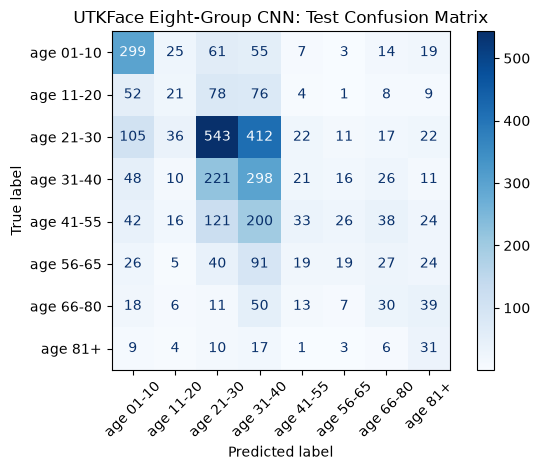

In [16]:
plt.figure(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    test_results["true_labels"],
    test_results["predicted_labels"],
    labels=list(range(len(LABEL_NAMES))),
    display_labels=LABEL_NAMES,
    xticks_rotation=45,
    cmap="Blues",
    values_format="d"
)

plt.title("UTKFace Eight-Group CNN: Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [17]:
from sklearn.metrics import confusion_matrix

# Save training history.
history_table.to_csv(
    "results/tables/UTKFace_8Groups_training_history.csv",
    index=False
)

# Save the classification report.
report_dictionary = classification_report(
    test_results["true_labels"],
    test_results["predicted_labels"],
    labels=list(range(len(LABEL_NAMES))),
    target_names=LABEL_NAMES,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report_dictionary).transpose().to_csv(
    "results/tables/UTKFace_8Groups_test_report.csv"
)

# Save the test confusion matrix.
confusion_matrix_table = pd.DataFrame(
    confusion_matrix(
        test_results["true_labels"],
        test_results["predicted_labels"],
        labels=list(range(len(LABEL_NAMES)))
    ),
    index=LABEL_NAMES,
    columns=LABEL_NAMES
)

confusion_matrix_table.to_csv(
    "results/tables/UTKFace_8Groups_confusion_matrix.csv"
)

print("Saved training history, test report, and confusion matrix.")

Saved training history, test report, and confusion matrix.
